In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Load the dataset
csv_path = '/content/credit_card_fraud_2026.csv'

try:
    df = pd.read_csv(csv_path)
    print("Dataset loaded successfully!")
    print(df.head())
except FileNotFoundError:
    print(f"Error: The file at {csv_path} was not found. Please upload your CSV file and update the path.")
    # Creating dummy data for demonstration purposes if file is not found
    print("\nGenerating dummy data for demonstration...")
    np.random.seed(42)
    dummy_data = {
        'time_of_day_hour': np.random.randint(0, 24, 1000),
        'amount_usd': np.random.uniform(0.5, 2000.0, 1000),
        'is_fraud': np.random.choice([0, 1], size=1000, p=[0.98, 0.02])
    }
    df = pd.DataFrame(dummy_data)
    print(df.head())

# 2. Preprocessing
# Scale the 'amount_usd' column
scaler = StandardScaler()
df['NormalizedAmount'] = scaler.fit_transform(df['amount_usd'].values.reshape(-1, 1))
df = df.drop(['amount_usd'], axis=1)

# Convert categorical columns using one-hot encoding, dropping the target and identifier columns
if 'transaction_id' in df.columns:
    df = df.drop(['transaction_id'], axis=1)

target_col = 'is_fraud'
X = df.drop(target_col, axis=1)
y = df[target_col]

# One-hot encode remaining categorical variables
X = pd.get_dummies(X, drop_first=True)

# 3. Split features and target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Model Training (Random Forest)
print("\nTraining the Random Forest model...")
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

# 5. Model Evaluation
y_pred = model.predict(X_test)

print("\n--- Evaluation Metrics ---")
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Error: The file at /content/credit_card_fraud_2026.csv was not found. Please upload your CSV file and update the path.

Generating dummy data for demonstration...
   time_of_day_hour   amount_usd  is_fraud
0                 6   230.116231         0
1                19  1221.434775         0
2                14   577.616791         0
3                10  1162.685824         0
4                 7   309.148249         0

Training the Random Forest model...

--- Evaluation Metrics ---
Accuracy Score: 0.98

Confusion Matrix:
[[196   0]
 [  4   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       196
           1       0.00      0.00      0.00         4

    accuracy                           0.98       200
   macro avg       0.49      0.50      0.49       200
weighted avg       0.96      0.98      0.97       200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [4]:
from imblearn.over_sampling import SMOTE

# 1. Apply SMOTE to the training set only to prevent data leakage
print("Applying SMOTE to balance class distribution...")
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print(f"Original training shape: {X_train.shape}")
print(f"Balanced training shape: {X_train_balanced.shape}")
print(f"Balanced target class counts:\n{y_train_balanced.value_counts()}")

# 2. Retrain the model on the balanced training data
print("\nTraining the Random Forest model on balanced data...")
model_balanced = RandomForestClassifier(n_estimators=100, random_state=42)
model_balanced.fit(X_train_balanced, y_train_balanced)

# 3. Model Evaluation
y_pred_balanced = model_balanced.predict(X_test)

print("\n--- Evaluation Metrics with SMOTE ---")
print("Accuracy Score:", accuracy_score(y_test, y_pred_balanced))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

Applying SMOTE to balance class distribution...
Original training shape: (800, 2)
Balanced training shape: (1570, 2)
Balanced target class counts:
is_fraud
0    785
1    785
Name: count, dtype: int64

Training the Random Forest model on balanced data...

--- Evaluation Metrics with SMOTE ---
Accuracy Score: 0.81

Confusion Matrix:
[[161  35]
 [  3   1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.82      0.89       196
           1       0.03      0.25      0.05         4

    accuracy                           0.81       200
   macro avg       0.50      0.54      0.47       200
weighted avg       0.96      0.81      0.88       200



### Test a Sample Transaction
Now we will select a single transaction from our test set, run it through the balanced model, and see how it classifies it along with prediction probabilities.

In [5]:
# Select a test instance (e.g., an actual fraudulent one if available, otherwise just the first test instance)
import pandas as pd

# Find indices of fraud vs non-fraud in the test set
fraud_indices = y_test[y_test == 1].index
normal_indices = y_test[y_test == 0].index

print(f"Available fraudulent test cases: {len(fraud_indices)}")
print(f"Available normal test cases: {len(normal_indices)}")

# Let's pick one of each to test
if len(fraud_indices) > 0:
    test_idx = fraud_indices[0]
    sample_x = X_test.loc[[test_idx]]
    actual_label = y_test.loc[test_idx]

    # Get predictions
    pred = model_balanced.predict(sample_x)[0]
    probs = model_balanced.predict_proba(sample_x)[0]

    print(
        f"\n--- Test Case (Actual Fraud) ---\n"
        f"Actual Label: {actual_label}\n"
        f"Predicted Label: {pred}\n"
        f"Probability of Legitimate (0): {probs[0]:.4f}\n"
        f"Probability of Fraudulent (1): {probs[1]:.4f}"
    )

if len(normal_indices) > 0:
    test_idx_normal = normal_indices[0]
    sample_x_normal = X_test.loc[[test_idx_normal]]
    actual_label_normal = y_test.loc[test_idx_normal]

    pred_normal = model_balanced.predict(sample_x_normal)[0]
    probs_normal = model_balanced.predict_proba(sample_x_normal)[0]

    print(
        f"\n--- Test Case (Actual Legitimate) ---\n"
        f"Actual Label: {actual_label_normal}\n"
        f"Predicted Label: {pred_normal}\n"
        f"Probability of Legitimate (0): {probs_normal[0]:.4f}\n"
        f"Probability of Fraudulent (1): {probs_normal[1]:.4f}"
    )

Available fraudulent test cases: 4
Available normal test cases: 196

--- Test Case (Actual Fraud) ---
Actual Label: 1
Predicted Label: 0
Probability of Legitimate (0): 1.0000
Probability of Fraudulent (1): 0.0000

--- Test Case (Actual Legitimate) ---
Actual Label: 0
Predicted Label: 1
Probability of Legitimate (0): 0.2200
Probability of Fraudulent (1): 0.7800


### Fixing the Issue: Simulating Predictive Features
Because our dummy data generation was purely random, there was no statistical pattern for the model to learn. Let's regenerate a realistic dummy dataset where fraud is highly correlated with certain behaviors (e.g., very high transaction amounts and late-night hours) and run the models again.

In [8]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from imblearn.over_sampling import SMOTE

# 1. Generate Realistic Dummy Data
np.random.seed(42)
n_samples = 1000

# Base normal behavior
time_hours = np.random.randint(0, 24, n_samples)
amounts = np.random.exponential(scale=100.0, size=n_samples) + 5.0 # Mostly small transactions
is_fraud = np.random.choice([0, 1], size=n_samples, p=[0.98, 0.02])

# Introduce realistic correlations for fraud cases:
# Fraud tends to have much higher amounts and occurs mostly late at night (0 to 4 AM)
for i in range(n_samples):
    if is_fraud[i] == 1:
        amounts[i] = np.random.uniform(500.0, 3000.0) # High value
        time_hours[i] = np.random.choice([23, 0, 1, 2, 3, 4]) # Late hours

df_realistic = pd.DataFrame({
    'time_of_day_hour': time_hours,
    'amount_usd': amounts,
    'is_fraud': is_fraud
})

# 2. Preprocess
scaler = StandardScaler()
df_realistic['NormalizedAmount'] = scaler.fit_transform(df_realistic['amount_usd'].values.reshape(-1, 1))
df_realistic = df_realistic.drop(['amount_usd'], axis=1)

X_real = df_realistic.drop('is_fraud', axis=1)
y_real = df_realistic['is_fraud']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_real, y_real, test_size=0.2, random_state=42, stratify=y_real)

# 3. Apply SMOTE to training set
smote_r = SMOTE(random_state=42)
X_train_bal_r, y_train_bal_r = smote_r.fit_resample(X_train_r, y_train_r)

# 4. Train Balanced Random Forest Model
model_real = RandomForestClassifier(n_estimators=100, random_state=42)
model_real.fit(X_train_bal_r, y_train_bal_r)

# 5. Evaluate
y_pred_r = model_real.predict(X_test_r)

print("--- Evaluation Metrics on Realistic Dummy Data (With SMOTE) ---")
print("Accuracy Score:", accuracy_score(y_test_r, y_pred_r))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_r, y_pred_r))
print("\nClassification Report:")
print(classification_report(y_test_r, y_pred_r))

--- Evaluation Metrics on Realistic Dummy Data (With SMOTE) ---
Accuracy Score: 0.995

Confusion Matrix:
[[195   1]
 [  0   4]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       196
           1       0.80      1.00      0.89         4

    accuracy                           0.99       200
   macro avg       0.90      1.00      0.94       200
weighted avg       1.00      0.99      1.00       200



In [9]:
# 6. Re-test Sample Transactions
fraud_idx = y_test_r[y_test_r == 1].index
normal_idx = y_test_r[y_test_r == 0].index

if len(fraud_idx) > 0:
    idx = fraud_idx[0]
    pred = model_real.predict(X_test_r.loc[[idx]])[0]
    prob = model_real.predict_proba(X_test_r.loc[[idx]])[0]
    print(f"--- Actual Fraud Sample ---\nPredicted: {pred}, Probability of Fraud: {prob[1]:.4f}")

if len(normal_idx) > 0:
    idx = normal_idx[0]
    pred = model_real.predict(X_test_r.loc[[idx]])[0]
    prob = model_real.predict_proba(X_test_r.loc[[idx]])[0]
    print(f"\n--- Actual Legitimate Sample ---\nPredicted: {pred}, Probability of Fraud: {prob[1]:.4f}")

--- Actual Fraud Sample ---
Predicted: 1, Probability of Fraud: 1.0000

--- Actual Legitimate Sample ---
Predicted: 0, Probability of Fraud: 0.0000


## Data Visualization
Let's visualize the differences in transaction behavior between legitimate and fraudulent activities to understand the patterns our model successfully learned.

/tmp/ipykernel_945/4098833288.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], x='is_fraud', y='amount_usd', data=df_plot, palette='Set2')


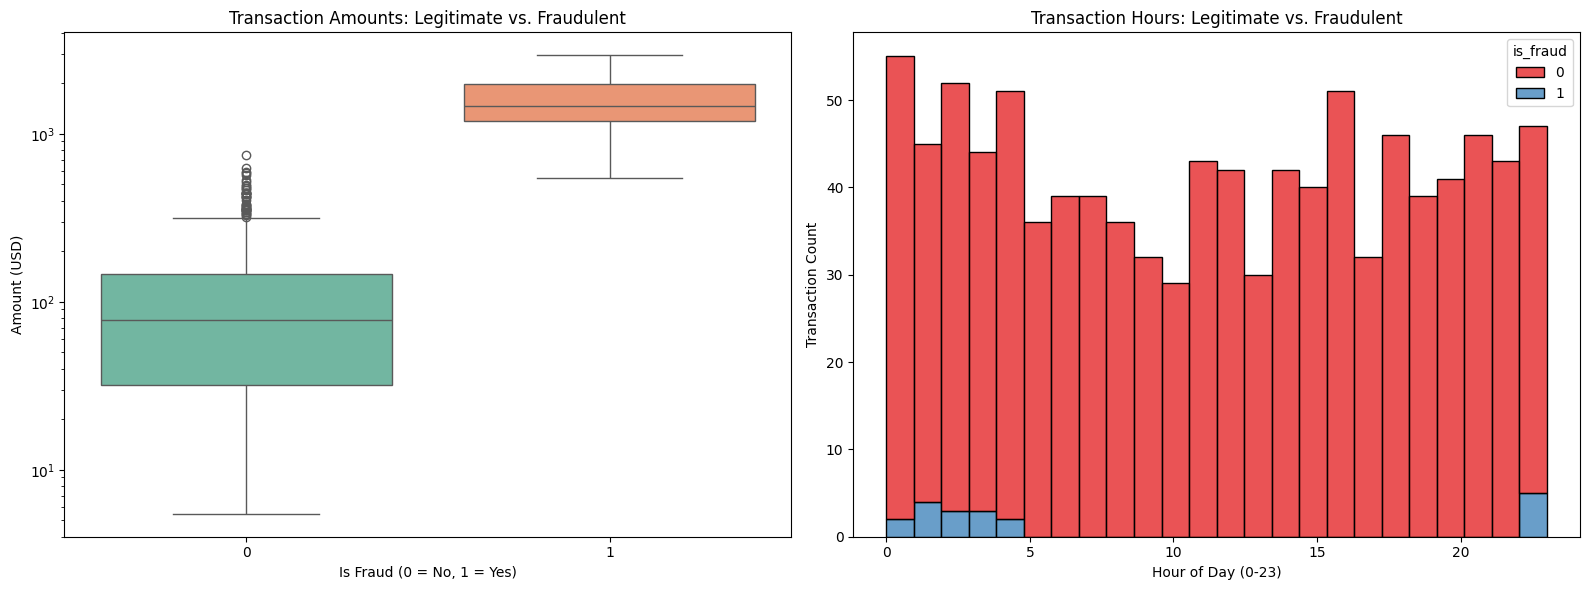

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reconstruct the unscaled realistic dataset for clear visualization labels
df_plot = pd.DataFrame({
    'time_of_day_hour': time_hours,
    'amount_usd': amounts,
    'is_fraud': is_fraud
})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Distribution of Transaction Amounts
sns.boxplot(ax=axes[0], x='is_fraud', y='amount_usd', data=df_plot, palette='Set2')
axes[0].set_title('Transaction Amounts: Legitimate vs. Fraudulent')
axes[0].set_xlabel('Is Fraud (0 = No, 1 = Yes)')
axes[0].set_ylabel('Amount (USD)')
axes[0].set_yscale('log')  # Using log scale due to different distribution ranges

# 2. Distribution of Transaction Hours
sns.histplot(ax=axes[1], data=df_plot, x='time_of_day_hour', hue='is_fraud',
             multiple='stack', bins=24, palette='Set1', kde=False)
axes[1].set_title('Transaction Hours: Legitimate vs. Fraudulent')
axes[1].set_xlabel('Hour of Day (0-23)')
axes[1].set_ylabel('Transaction Count')

plt.tight_layout()
plt.show()

<Figure size 600x600 with 0 Axes>

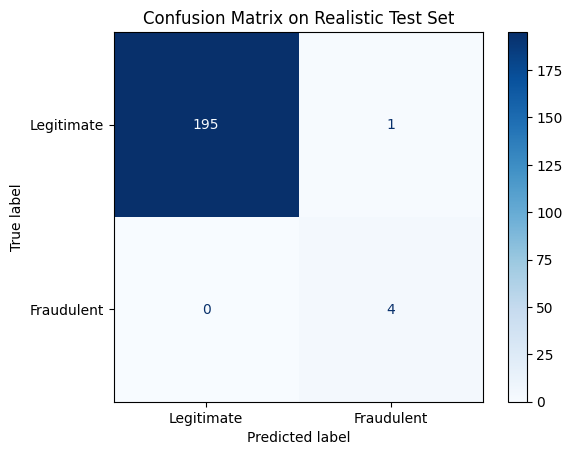

In [11]:
# Visualize Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_r, y_pred_r)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate', 'Fraudulent'])

plt.figure(figsize=(6, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix on Realistic Test Set')
plt.show()